In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

In [7]:

df = pd.read_csv("Social_Network_Ads.csv")
df.shape
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [9]:
df.isna().sum()

User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

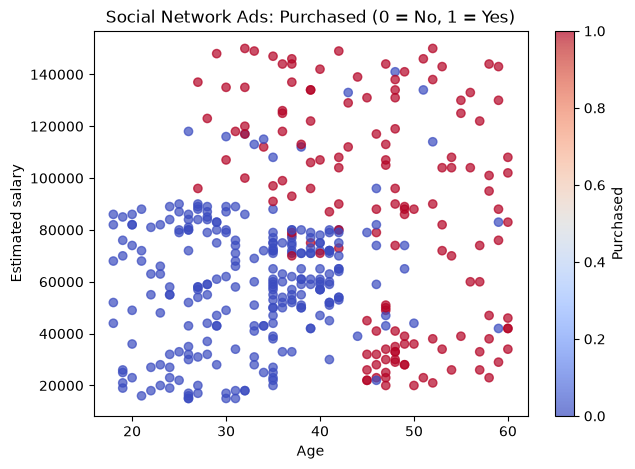

In [10]:
plt.figure(figsize=(7, 5))
plt.scatter(df["Age"], df["EstimatedSalary"],
            c=df["Purchased"], cmap="coolwarm", alpha=0.7)
plt.xlabel("Age")
plt.ylabel("Estimated salary")
plt.title("Social Network Ads: Purchased (0 = No, 1 = Yes)")
plt.colorbar(label="Purchased")
plt.show()

In [11]:
X = df[["Age", "EstimatedSalary"]]
y = df["Purchased"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (400, 2)
y shape: (400,)


In [12]:
X_train , X_test , y_train , y_test = train_test_split(
    X,y,test_size=0.20,stratify=y , random_state=42
)

In [14]:
print(len(X_train))
print(len(X_test))

320
80


In [20]:
base = DecisionTreeClassifier(random_state=42)
base.fit(X_train,y_train)
print(base.score(X_train,y_train))
print(base.get_depth())

print(base.get_n_leaves())


0.99375
11
46


In [21]:
baseline_scores = cross_val_score(
    base, X_train, y_train, cv=5, scoring="accuracy"
)
print("Accuracy for each fold:", baseline_scores.round(3))
print("Mean baseline CV accuracy:", round(baseline_scores.mean(), 3))

Accuracy for each fold: [0.953 0.781 0.938 0.828 0.859]
Mean baseline CV accuracy: 0.872


In [24]:
pram_grid ={
    "criterion" : ["gini" ,"entropy"],
    "max_depth" : [2,3,4,5,None],
    "min_samples_leaf": [1, 2, 4, 6]
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid = pram_grid,
    scoring= "accuracy",
    cv=5,
    return_train_score=True,
    refit=True,
    n_jobs=1

)

grid.fit(X_train,y_train)
print(grid.best_params_)
print(grid.best_score_)

{'criterion': 'gini', 'max_depth': 2, 'min_samples_leaf': 1}
0.91875


In [25]:
results = pd.DataFrame(grid.cv_results_)
columns = ["param_criterion", "param_max_depth", "param_min_samples_leaf",
           "mean_train_score", "mean_test_score"]
display(results[columns].sort_values("mean_test_score", ascending=False).head(10).round(3))

,param_criterion,param_max_depth,param_min_samples_leaf,mean_train_score,mean_test_score
0,gini,2,1,0.923,0.919
1,gini,2,2,0.923,0.919
2,gini,2,4,0.923,0.919
3,gini,2,6,0.923,0.919
23,entropy,2,6,0.923,0.919
22,entropy,2,4,0.923,0.919
21,entropy,2,2,0.923,0.919
20,entropy,2,1,0.923,0.919
31,entropy,4,6,0.937,0.919
35,entropy,5,6,0.939,0.916


Best tree depth: 2
Best tree leaves: 4


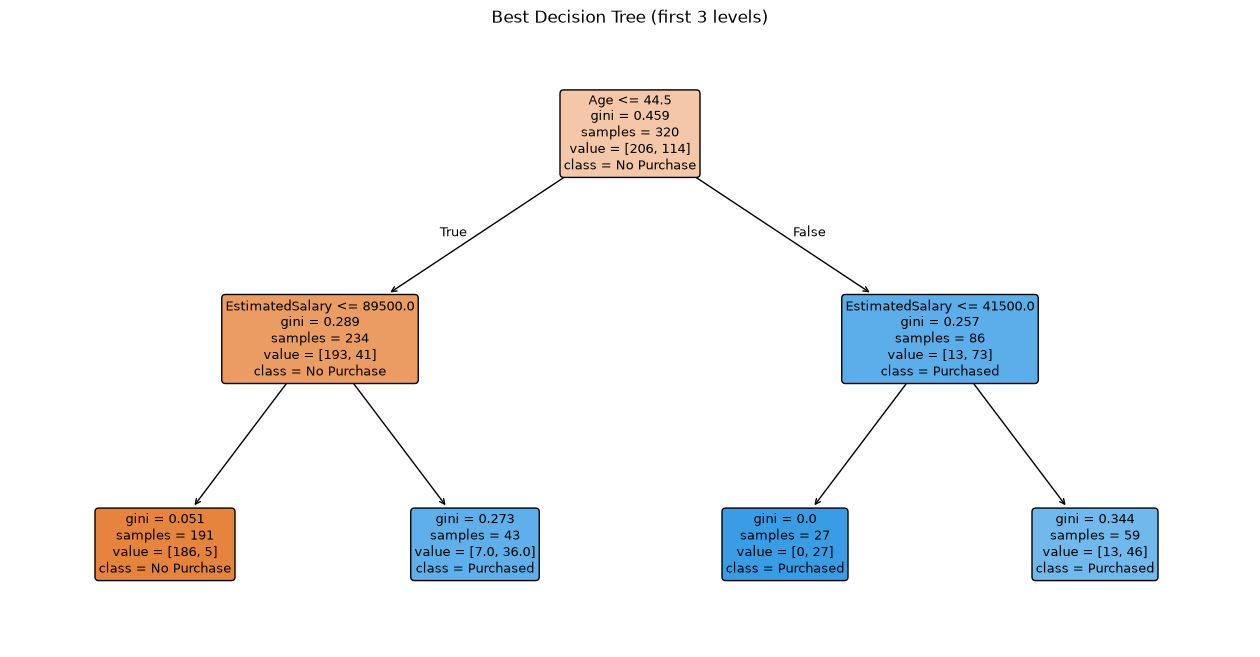

In [26]:
best_tree = grid.best_estimator_

print("Best tree depth:", best_tree.get_depth())
print("Best tree leaves:", best_tree.get_n_leaves())

plt.figure(figsize=(16, 8))
plot_tree(best_tree,
          feature_names=X.columns,
          class_names=["No Purchase", "Purchased"],
          filled=True, rounded=True,
          max_depth=3, fontsize=9)
plt.title("Best Decision Tree (first 3 levels)")
plt.show()

In [27]:
y_pred = best_tree.predict(X_test)
print(accuracy_score(y_test,y_pred))

print(classification_report(y_test,y_pred,target_names=["No Purchase", "Purchased"]))


0.8875
              precision    recall  f1-score   support

 No Purchase       0.94      0.88      0.91        51
   Purchased       0.81      0.90      0.85        29

    accuracy                           0.89        80
   macro avg       0.88      0.89      0.88        80
weighted avg       0.89      0.89      0.89        80



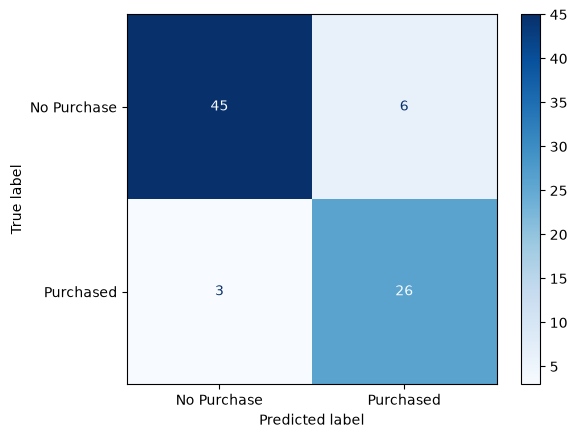

In [28]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["No Purchase", "Purchased"],
    cmap="Blues"
)

In [29]:
new_person = pd.DataFrame({"Age": [42], "EstimatedSalary": [90000]})

prediction = best_tree.predict(new_person)
probabilities = best_tree.predict_proba(new_person)

In [30]:
print(prediction)

[1]
